# LAB 05: HOG-Based Industrial Defect Detection and Classification

**Pipeline:** `Image → Preprocessing → HOG Feature Extraction → ML Classifier → Defective / Non-Defective decision`

**Contents**
1. Setup & configuration
2. Load and inspect the dataset
3. Build the binary dataset (Normal vs Defective) + multi-class dataset
4. Preprocessing (grayscale + resize)
5. HOG feature extraction & visualisation
6. Classifiers: SVM, Random Forest, k-NN
7. Evaluation: confusion matrix, classification report, metrics
8. HOG parameter study (cell size × orientations)
9. Robustness experiments (brightness, noise, blur, rotation)
10. Advanced: multi-class defect-type classification
11. Industrial quality-control decision module
12. Bonus: real-time webcam / video prototype
13. Notes for the report

> **Dataset note.** NEU-DET contains 6 defect types (crazing, inclusion, patches, pitted_surface, rolled-in_scale, scratches) and **no defect-free images**.
> To get a real *Normal* class, the binary task uses **bounding-box crops as "Defective"** and **same-size defect-free windows (no overlap with any annotated box) from the same steel images as "Normal"**. Because both classes are cut from the same images with matched crop sizes, the classifier cannot cheat on image size or acquisition differences.

## 1. Setup & configuration

In [1]:
# !pip install kagglehub scikit-image opencv-python scikit-learn matplotlib seaborn pandas joblib
import re, time, warnings, random
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
import joblib

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- configuration ----------------
DATA_DIR  = None     # set to a local folder to skip the Kaggle download, e.g. r"C:\data\neu-det"
IMG_SIZE  = 64       # common resolution for the binary (crop) task
IMG_SIZE_MC = 128    # common resolution for the multi-class (whole image) task
MIN_SIDE  = 32       # minimum crop side in pixels
THRESH    = 0.50     # P(defect) >= THRESH  ->  REJECT
GRID_N    = 2000     # training crops used for the HOG parameter sweep (stratified subsample, for speed)
N_TREES   = 200      # Random Forest size
RUN_WEBCAM = False   # bonus section; set True on a machine with a camera
plt.rcParams["figure.dpi"] = 100

## 2. Load and inspect the dataset

In [2]:
# The Kaggle snippet in the lab sheet (kagglehub.load_dataset + PANDAS adapter) is for tabular files.
# This dataset is images + XML, so we download the folder with dataset_download instead.
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("sovitrath/neu-steel-surface-defect-detect-trainvalid-split")
DATA_ROOT = Path(DATA_DIR)
print("Dataset root:", DATA_ROOT)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
def split_of(p):
    # tokenise every folder name so "train", "train_images", "valid-annotations" ... are all recognised
    toks = [t for s in p.relative_to(DATA_ROOT).parts[:-1] for t in re.split(r"[^a-z0-9]+", s.lower()) if t]
    if "train" in toks: return "train"
    if any(t in ("valid", "val", "validation", "test") for t in toks): return "valid"
    return None
def label_of(stem):
    # "crazing_1", "rolled-in_scale_12", "scratches_3_jpg.rf.abc" -> class name
    m = re.match(r"^([a-z\-]+(?:_[a-z\-]+)*)_\d+", stem, re.I)
    return m.group(1) if m else None
# key = (split, filename stem) so identical names in train/ and valid/ can never be mixed up
xml_map = {(split_of(p), p.stem): p for p in DATA_ROOT.rglob("*.xml")}

rows = []
for p in DATA_ROOT.rglob("*"):
    if p.suffix.lower() not in IMG_EXT:
        continue
    split, label = split_of(p), label_of(p.stem)
    if split is None or label is None: continue
    rows.append(dict(path=p, split=split, label=label, xml=xml_map.get((split, p.stem))))

if not rows:
    found = [str(p.relative_to(DATA_ROOT)) for p in DATA_ROOT.rglob("*") if p.suffix.lower() in IMG_EXT][:8]
    raise RuntimeError(f"No images matched under {DATA_ROOT}. First image files found: {found}. "
                       "Adjust split_of()/label_of() to this folder layout.")
df = pd.DataFrame(rows).sort_values("path").reset_index(drop=True)

CLASSES = sorted(df.label.unique())
print(f"{len(df)} images | {len(CLASSES)} classes: {CLASSES}")
print("Images with XML annotation:", df.xml.notna().sum())
display(pd.crosstab(df.label, df.split, margins=True))

100%|██████████| 26.3M/26.3M [00:00<00:00, 107MB/s]

Extracting files...


Dataset root: /root/.cache/kagglehub/datasets/sovitrath/neu-steel-surface-defect-detect-trainvalid-split/versions/1
1800 images | 6 classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Images with XML annotation: 1800


split,train,valid,All
label,,,
crazing,283,17,300
inclusion,283,17,300
patches,284,16,300
pitted_surface,283,17,300
rolled-in_scale,283,17,300
scratches,284,16,300
All,1700,100,1800


Example image shape: (200, 200, 3) dtype: uint8


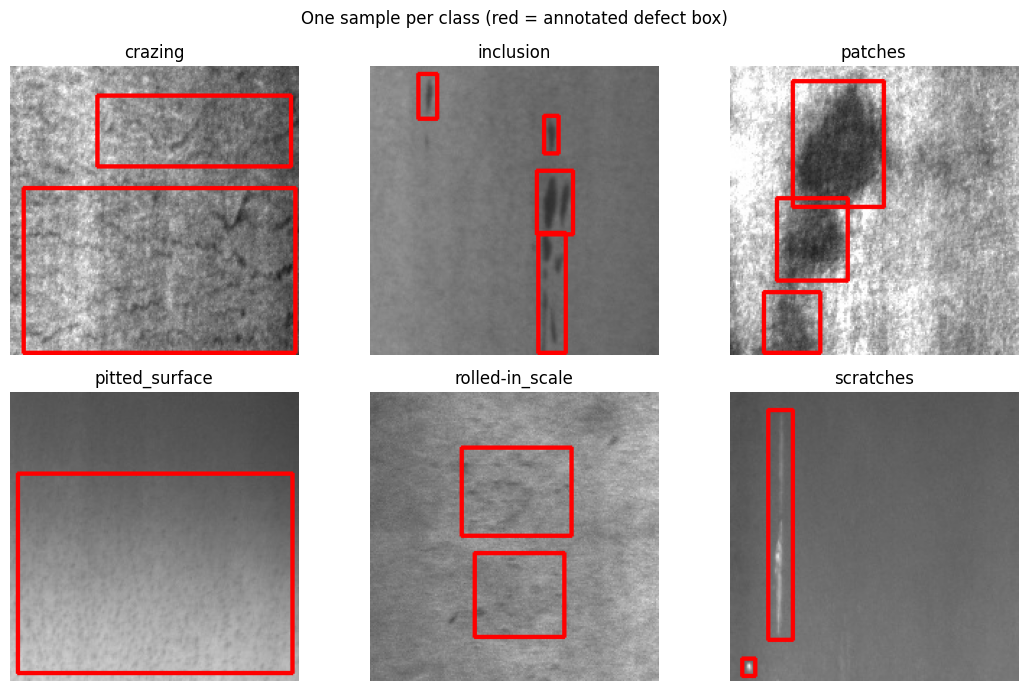

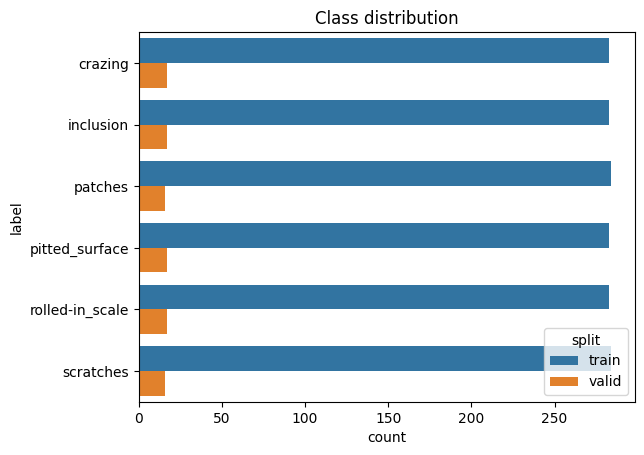

In [3]:
# Image properties + sample grid (one per class)
im = cv2.imread(str(df.path[0]), cv2.IMREAD_UNCHANGED)
print("Example image shape:", im.shape, "dtype:", im.dtype)

def read_gray(p):
    g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    assert g is not None, p
    return g

def parse_xml(p):
    boxes = []
    if p is None: return boxes
    for o in ET.parse(p).getroot().iter("object"):
        b = o.find("bndbox")
        boxes.append(tuple(int(float(b.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax")))
    return boxes

fig, ax = plt.subplots(2, 3, figsize=(11, 7))
for a, c in zip(ax.ravel(), CLASSES):
    r = df[(df.label == c) & (df.split == "train")].iloc[0]
    g = cv2.cvtColor(read_gray(r.path), cv2.COLOR_GRAY2RGB)
    for (x1, y1, x2, y2) in parse_xml(r.xml):
        cv2.rectangle(g, (x1, y1), (x2, y2), (255, 0, 0), 2)
    a.imshow(g); a.set_title(c); a.axis("off")
plt.suptitle("One sample per class (red = annotated defect box)"); plt.tight_layout(); plt.show()

sns.countplot(data=df, y="label", hue="split"); plt.title("Class distribution"); plt.show()

## 3. Build the datasets

* **Binary (Class 0 = Normal, Class 1 = Defective):** for every annotated box → one *Defective* square crop; plus one *Normal* square crop of the same size from a random location that does not overlap any box.
* **Multi-class (advanced):** whole images with the defect-type label.

In [4]:
def square_window(box, H, W):
    x1, y1, x2, y2 = box
    side = int(min(max(x2 - x1, y2 - y1, MIN_SIDE), H, W))
    cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
    x0 = int(np.clip(cx - side // 2, 0, W - side)); y0 = int(np.clip(cy - side // 2, 0, H - side))
    return x0, y0, side

def overlap_frac(x0, y0, s, boxes):
    # fraction of the window covered by the union (approximate: max over boxes)
    best = 0.0
    for (a, b, c, d) in boxes:
        iw = max(0, min(x0 + s, c) - max(x0, a)); ih = max(0, min(y0 + s, d) - max(y0, b))
        best = max(best, iw * ih / (s * s))
    return best

def find_normal_window(side, boxes, H, W, rng, tries=80, max_overlap=0.02):
    if side >= min(H, W): return None
    for _ in range(tries):
        x0 = int(rng.integers(0, W - side + 1)); y0 = int(rng.integers(0, H - side + 1))
        if overlap_frac(x0, y0, side, boxes) <= max_overlap:
            return x0, y0, side
    return None

def make_binary(frame, seed=SEED):
    rng = np.random.default_rng(seed)
    X, y, meta = [], [], []
    for r in frame.itertuples():
        boxes = parse_xml(r.xml)
        if not boxes: continue
        img = read_gray(r.path); H, W = img.shape
        for box in boxes:
            x0, y0, s = square_window(box, H, W)
            crop = cv2.resize(img[y0:y0+s, x0:x0+s], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
            X.append(crop); y.append(1); meta.append((r.label, s))
            nw = find_normal_window(s, boxes, H, W, rng)
            if nw is not None:
                nx, ny, ns = nw
                crop = cv2.resize(img[ny:ny+ns, nx:nx+ns], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
                X.append(crop); y.append(0); meta.append(("normal", ns))
    return np.array(X, np.uint8), np.array(y), meta

t0 = time.time()
Xtr_img, ytr, mtr = make_binary(df[df.split == "train"])
Xte_img, yte, mte = make_binary(df[df.split == "valid"], seed=SEED + 1)
print(f"Built in {time.time()-t0:.1f}s | train {Xtr_img.shape} | test {Xte_img.shape}")
print("Train  normal/defective:", np.bincount(ytr), "| Test normal/defective:", np.bincount(yte))

Built in 7.1s | train (5441, 64, 64) | test (306, 64, 64)
Train  normal/defective: [1484 3957] | Test normal/defective: [ 74 232]


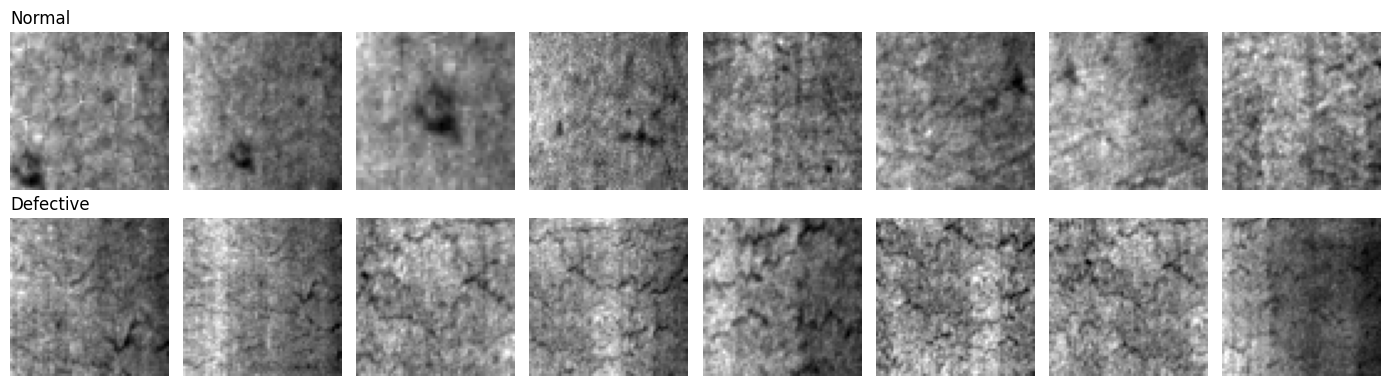

In [5]:
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for k, cls in enumerate([0, 1]):
    idx = np.where(ytr == cls)[0][:8]
    for a, i in zip(ax[k], idx):
        a.imshow(Xtr_img[i], cmap="gray"); a.axis("off")
    ax[k][0].set_title("Normal" if cls == 0 else "Defective", loc="left")
plt.tight_layout(); plt.show()

## 4. Preprocessing
Images are already read as **grayscale** (`cv2.IMREAD_GRAYSCALE`) and every crop is **resized to a common resolution** (`IMG_SIZE × IMG_SIZE`, area interpolation). The same `preprocess()` function is reused for robustness tests, the QC module and the webcam demo.

In [6]:
def preprocess(img, size=IMG_SIZE):
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if img.shape[:2] != (size, size):
        img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return img.astype(np.uint8)
print("preprocess OK ->", preprocess(Xtr_img[0]).shape)

preprocess OK -> (64, 64)


## 5. HOG feature extraction & visualisation

In [7]:
def hog_feat(img, ppc=8, ori=9, cpb=2, visualize=False):
    return hog(preprocess(img, img.shape[0]) if img.ndim == 3 else img,
               orientations=ori, pixels_per_cell=(ppc, ppc), cells_per_block=(cpb, cpb),
               block_norm="L2-Hys", feature_vector=True, visualize=visualize)

def extract(imgs, ppc=8, ori=9):
    # HOG per image is independent -> spread over all CPU cores
    feats = joblib.Parallel(n_jobs=-1, batch_size=64)(joblib.delayed(hog_feat)(i, ppc, ori) for i in imgs)
    return np.array(feats, dtype=np.float32)

print("Feature length (8x8 cells, 9 orient.):", hog_feat(Xtr_img[0]).shape[0])
for ppc in (4, 8, 16):
    print(f"  cell {ppc}x{ppc}: ", hog_feat(Xtr_img[0], ppc=ppc).shape[0], "dims")

Feature length (8x8 cells, 9 orient.): 1764
  cell 4x4:  8100 dims
  cell 8x8:  1764 dims
  cell 16x16:  324 dims


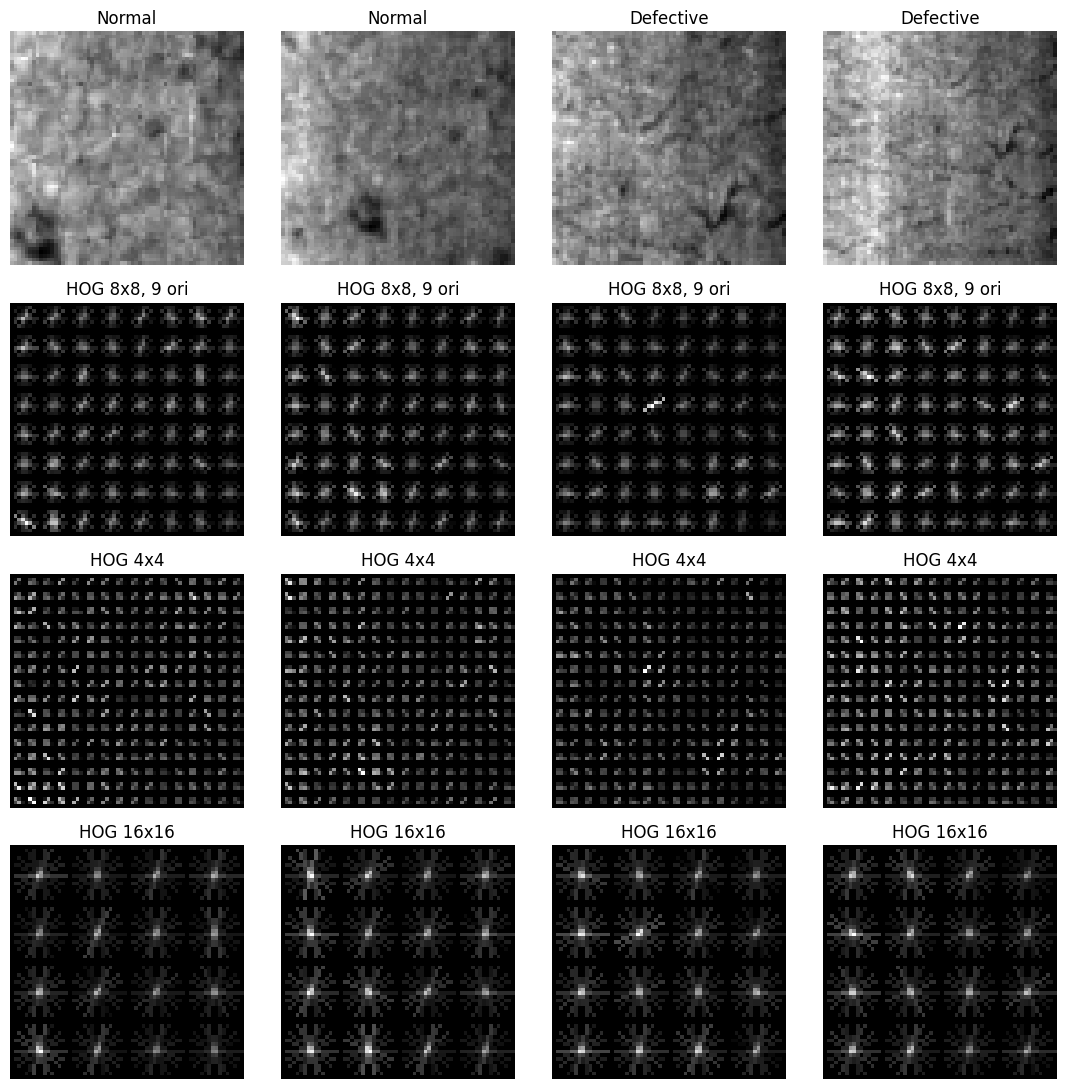

In [8]:
from skimage import exposure
fig, ax = plt.subplots(4, 4, figsize=(11, 11))
picks = [np.where(ytr == 0)[0][0], np.where(ytr == 0)[0][1], np.where(ytr == 1)[0][0], np.where(ytr == 1)[0][1]]
for c, i in enumerate(picks):
    f, vis = hog_feat(Xtr_img[i], visualize=True)
    vis = exposure.rescale_intensity(vis, in_range=(0, vis.max() + 1e-9))
    ax[0][c].imshow(Xtr_img[i], cmap="gray"); ax[0][c].set_title(("Normal" if ytr[i]==0 else "Defective")); ax[0][c].axis("off")
    ax[1][c].imshow(vis, cmap="gray"); ax[1][c].set_title("HOG 8x8, 9 ori"); ax[1][c].axis("off")
    for r, ppc in ((2, 4), (3, 16)):
        _, v = hog_feat(Xtr_img[i], ppc=ppc, visualize=True)
        ax[r][c].imshow(exposure.rescale_intensity(v, in_range=(0, v.max() + 1e-9)), cmap="gray")
        ax[r][c].set_title(f"HOG {ppc}x{ppc}"); ax[r][c].axis("off")
plt.tight_layout(); plt.show()

## 6. Classifiers (HOG + SVM, HOG + Random Forest, HOG + k-NN)

In [9]:
def make_svm(prob=False, C=10):
    # large kernel cache: the whole train kernel fits in RAM, so libsvm does not recompute it (big speed-up)
    svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C, gamma="scale", class_weight="balanced",
                                              cache_size=1000, random_state=SEED))
    if not prob:
        return svm
    # Platt-scaled probabilities from a 3-fold CV run in parallel; much cheaper than SVC(probability=True),
    # which runs an extra 5-fold CV inside libsvm on a single core
    return CalibratedClassifierCV(svm, method="sigmoid", cv=3, ensemble=False, n_jobs=-1)
def make_rf(n_estimators=N_TREES):
    return RandomForestClassifier(n_estimators=n_estimators, class_weight="balanced", n_jobs=-1, random_state=SEED)
def make_knn():
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, weights="distance"))

def metrics(y_true, y_pred, average="binary"):
    kw = dict(average=average, zero_division=0)
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, **kw),
                recall=recall_score(y_true, y_pred, **kw), f1=f1_score(y_true, y_pred, **kw))

# baseline: 8x8 cells, 9 orientations
Ftr = extract(Xtr_img); Fte = extract(Xte_img)
res = {}
for name, mk in {"HOG + SVM (RBF)": make_svm, "HOG + Random Forest": make_rf, "HOG + k-NN": make_knn}.items():
    t0 = time.time(); m = mk().fit(Ftr, ytr); t_fit = time.time() - t0
    t0 = time.time(); pred = m.predict(Fte); t_pred = (time.time() - t0) / len(Fte) * 1000
    res[name] = dict(model=m, pred=pred, **metrics(yte, pred), fit_s=t_fit, ms_per_img=t_pred)
comparison = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk not in ("model", "pred")} for k, v in res.items()}).T
display(comparison.round(4))

,accuracy,precision,recall,f1,fit_s,ms_per_img
HOG + SVM (RBF),0.8137,0.8543,0.9095,0.8810,37.7286,6.9876
HOG + Random Forest,0.8203,0.8127,0.9914,0.8932,54.7341,0.2177
HOG + k-NN,0.7255,0.8190,0.8190,0.8190,0.1421,0.8616


## 7. Evaluation: confusion matrices & classification reports

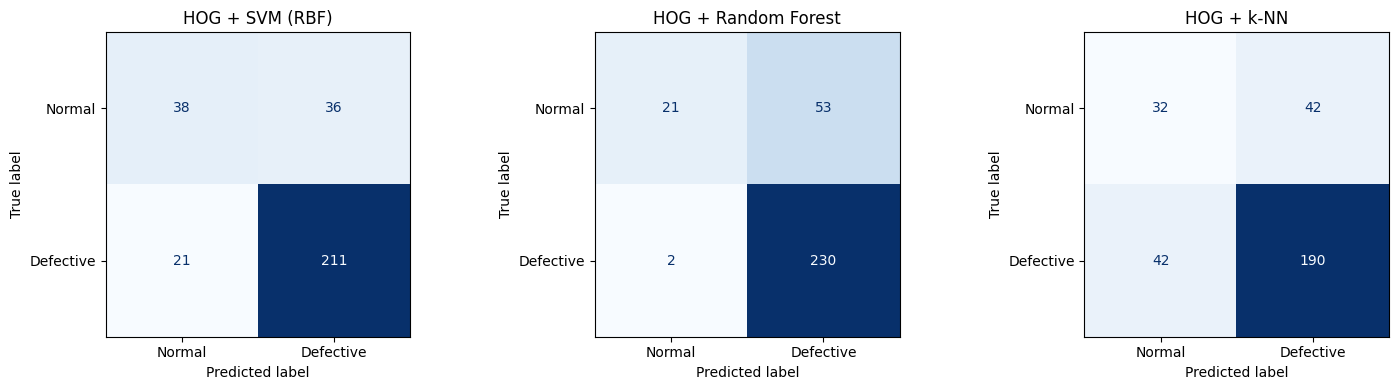

 HOG + SVM (RBF) 
               precision    recall  f1-score   support

      Normal     0.6441    0.5135    0.5714        74
   Defective     0.8543    0.9095    0.8810       232

    accuracy                         0.8137       306
   macro avg     0.7492    0.7115    0.7262       306
weighted avg     0.8034    0.8137    0.8061       306

 HOG + Random Forest 
               precision    recall  f1-score   support

      Normal     0.9130    0.2838    0.4330        74
   Defective     0.8127    0.9914    0.8932       232

    accuracy                         0.8203       306
   macro avg     0.8629    0.6376    0.6631       306
weighted avg     0.8370    0.8203    0.7819       306

 HOG + k-NN 
               precision    recall  f1-score   support

      Normal     0.4324    0.4324    0.4324        74
   Defective     0.8190    0.8190    0.8190       232

    accuracy                         0.7255       306
   macro avg     0.6257    0.6257    0.6257       306
weighted avg     0

In [10]:
fig, ax = plt.subplots(1, len(res), figsize=(5 * len(res), 4))
for a, (name, r) in zip(np.atleast_1d(ax), res.items()):
    ConfusionMatrixDisplay(confusion_matrix(yte, r["pred"]), display_labels=["Normal", "Defective"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.show()
for name, r in res.items():
    print("=" * 60, "\n", name, "\n", classification_report(yte, r["pred"], target_names=["Normal", "Defective"], digits=4))

## 8. HOG parameter study: cell size (4, 8, 16) × orientations (6, 9, 12)
Each configuration is scored with **3-fold CV F1 on the training set** (used for model selection) and **F1 on the held-out validation split** (reported result). Selection uses CV only, so the test split is not tuned on.

For speed, the sweep trains on a **stratified subsample of `GRID_N` training crops** (SVM cost grows roughly with n²) and uses a 100-tree forest; the full validation split is still used for testing. The final models after the sweep are trained on the **full** training set.

Sweep uses 2000 of 5441 training crops (normal/defective: [ 545 1455])
cell  4 ori  6 dims   5400  SVM cvF1=0.875 testF1=0.862 | RF testF1=0.866  [83s elapsed]
cell  4 ori  9 dims   8100  SVM cvF1=0.868 testF1=0.869 | RF testF1=0.869  [194s elapsed]
cell  4 ori 12 dims  10800  SVM cvF1=0.888 testF1=0.871 | RF testF1=0.875  [359s elapsed]
cell  8 ori  6 dims   1176  SVM cvF1=0.869 testF1=0.869 | RF testF1=0.886  [378s elapsed]
cell  8 ori  9 dims   1764  SVM cvF1=0.875 testF1=0.873 | RF testF1=0.880  [405s elapsed]
cell  8 ori 12 dims   2352  SVM cvF1=0.886 testF1=0.882 | RF testF1=0.893  [437s elapsed]
cell 16 ori  6 dims    216  SVM cvF1=0.870 testF1=0.871 | RF testF1=0.896  [444s elapsed]
cell 16 ori  9 dims    324  SVM cvF1=0.877 testF1=0.871 | RF testF1=0.903  [451s elapsed]
cell 16 ori 12 dims    432  SVM cvF1=0.882 testF1=0.882 | RF testF1=0.907  [460s elapsed]


,cell,orient,dims,svm_cv_f1,svm_acc,svm_f1,rf_acc,rf_f1
0,4x4,6,5400,0.8754,0.7778,0.8618,0.7647,0.8657
1,4x4,9,8100,0.8680,0.7876,0.8692,0.7712,0.8689
2,4x4,12,10800,0.8885,0.7908,0.8715,0.7843,0.8750
3,8x8,6,1176,0.8693,0.7974,0.8692,0.8072,0.8863
4,8x8,9,1764,0.8751,0.8007,0.8727,0.7941,0.8795
5,8x8,12,2352,0.8862,0.8137,0.8825,0.8203,0.8932
6,16x16,6,216,0.8698,0.8039,0.8712,0.8301,0.8956
7,16x16,9,324,0.8765,0.8039,0.8712,0.8399,0.9030
8,16x16,12,432,0.8818,0.8170,0.8824,0.8464,0.9066


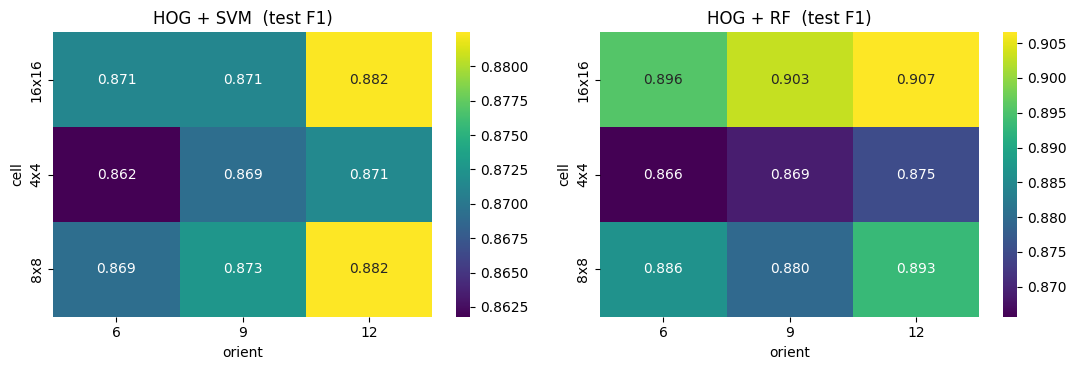

Selected by CV  ->  cell 4x4, 12 orientations


In [11]:
grid_rows = []
skf = StratifiedKFold(3, shuffle=True, random_state=SEED)
GRID_TREES = 100          # smaller forest for the sweep only; trends are the same
sub = (np.arange(len(ytr)) if len(ytr) <= GRID_N else
       train_test_split(np.arange(len(ytr)), train_size=GRID_N, stratify=ytr, random_state=SEED)[0])
Xg_img, yg = Xtr_img[sub], ytr[sub]
print(f"Sweep uses {len(yg)} of {len(ytr)} training crops (normal/defective: {np.bincount(yg)})")
t_grid = time.time()
for ppc in (4, 8, 16):
    for ori in (6, 9, 12):
        A = extract(Xg_img, ppc, ori); B = extract(Xte_img, ppc, ori)
        cv_f1 = cross_val_score(make_svm(), A, yg, cv=skf, scoring="f1", n_jobs=-1).mean()
        svm = make_svm().fit(A, yg); rf = make_rf(GRID_TREES).fit(A, yg)
        ms, mr = metrics(yte, svm.predict(B)), metrics(yte, rf.predict(B))
        grid_rows.append(dict(cell=f"{ppc}x{ppc}", orient=ori, dims=A.shape[1], svm_cv_f1=cv_f1,
                              svm_acc=ms["accuracy"], svm_f1=ms["f1"], rf_acc=mr["accuracy"], rf_f1=mr["f1"]))
        print(f"cell {ppc:>2} ori {ori:>2} dims {A.shape[1]:>6}  SVM cvF1={cv_f1:.3f} testF1={ms['f1']:.3f} | RF testF1={mr['f1']:.3f}"
              f"  [{time.time()-t_grid:.0f}s elapsed]")
grid = pd.DataFrame(grid_rows)
display(grid.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, col, t in zip(ax, ("svm_f1", "rf_f1"), ("HOG + SVM  (test F1)", "HOG + RF  (test F1)")):
    sns.heatmap(grid.pivot(index="cell", columns="orient", values=col), annot=True, fmt=".3f", cmap="viridis", ax=a); a.set_title(t)
plt.tight_layout(); plt.show()

best = grid.sort_values("svm_cv_f1", ascending=False).iloc[0]
BEST_PPC, BEST_ORI = int(best.cell.split("x")[0]), int(best.orient)
print(f"Selected by CV  ->  cell {BEST_PPC}x{BEST_PPC}, {BEST_ORI} orientations")

In [12]:
# Final models with selected HOG parameters, trained on the full training set
# (SVM with Platt-calibrated probabilities for confidence scores)
t0 = time.time()
Ftr = extract(Xtr_img, BEST_PPC, BEST_ORI); Fte = extract(Xte_img, BEST_PPC, BEST_ORI)
svm_final = make_svm(prob=True).fit(Ftr, ytr)
rf_final  = make_rf().fit(Ftr, ytr)
print(f"Final models trained in {time.time()-t0:.0f}s")
for n, m in (("SVM", svm_final), ("RF", rf_final)):
    p = m.predict(Fte); print(n, {k: round(v, 4) for k, v in metrics(yte, p).items()})
print(classification_report(yte, svm_final.predict(Fte), target_names=["Normal", "Defective"], digits=4))
joblib.dump(dict(model=svm_final, ppc=BEST_PPC, ori=BEST_ORI, size=IMG_SIZE, thresh=THRESH), "hog_svm_defect_model.joblib")

Final models trained in 863s
SVM {'accuracy': 0.8137, 'precision': 0.8253, 'recall': 0.9569, 'f1': 0.8862}
RF {'accuracy': 0.7908, 'precision': 0.7857, 'recall': 0.9957, 'f1': 0.8783}
              precision    recall  f1-score   support

      Normal     0.7297    0.3649    0.4865        74
   Defective     0.8253    0.9569    0.8862       232

    accuracy                         0.8137       306
   macro avg     0.7775    0.6609    0.6864       306
weighted avg     0.8022    0.8137    0.7896       306



['hog_svm_defect_model.joblib']

## 9. Robustness experiments
The trained models are **not retrained**; the *test* crops are corrupted and re-evaluated (brightness, Gaussian noise, blur, rotation). Reported: accuracy/F1 and their change vs. the clean test set.

,condition,model,accuracy,f1,d_acc,d_f1
0,Clean,SVM,0.8137,0.8862,0.0000,0.0000
1,Clean,RF,0.7908,0.8783,0.0000,0.0000
2,Brightness x0.6,SVM,0.8007,0.8688,-0.0131,-0.0174
3,Brightness x0.6,RF,0.8203,0.8932,0.0294,0.0149
4,Brightness x1.4,SVM,0.8170,0.8893,0.0033,0.0031
5,Brightness x1.4,RF,0.7810,0.8733,-0.0098,-0.0050
6,Noise sigma=10,SVM,0.7582,0.8614,-0.0556,-0.0248
7,Noise sigma=10,RF,0.7582,0.8625,-0.0327,-0.0159
8,Noise sigma=25,SVM,0.7516,0.8582,-0.0621,-0.0280
9,Noise sigma=25,RF,0.7582,0.8625,-0.0327,-0.0159


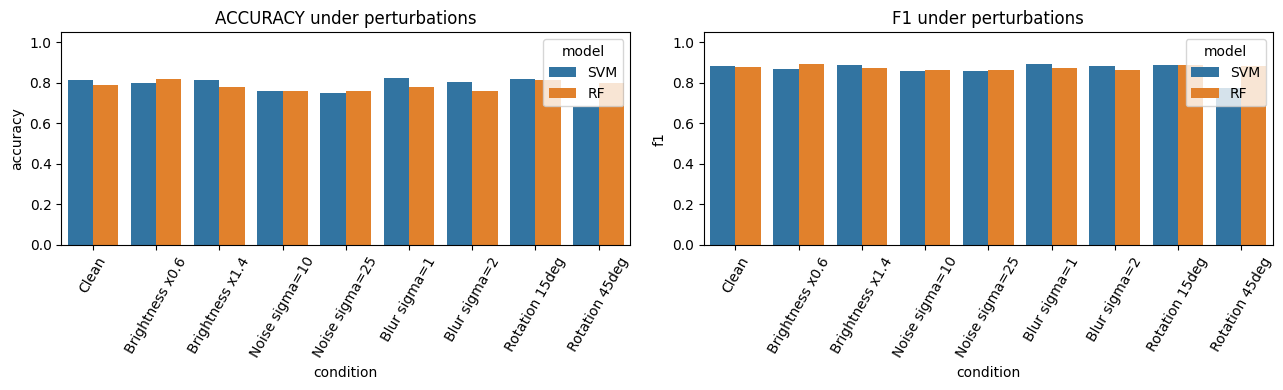

In [13]:
def brightness(img, f):  return np.clip(img.astype(np.float32) * f, 0, 255).astype(np.uint8)
def gnoise(img, s, rng): return np.clip(img.astype(np.float32) + rng.normal(0, s, img.shape), 0, 255).astype(np.uint8)
def gblur(img, s):       return cv2.GaussianBlur(img, (0, 0), s)
def rotate(img, a):
    h, w = img.shape; M = cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

rng = np.random.default_rng(SEED)
conditions = {
    "Clean": lambda x: x,
    "Brightness x0.6": lambda x: brightness(x, 0.6), "Brightness x1.4": lambda x: brightness(x, 1.4),
    "Noise sigma=10": lambda x: gnoise(x, 10, rng),  "Noise sigma=25": lambda x: gnoise(x, 25, rng),
    "Blur sigma=1": lambda x: gblur(x, 1.0),         "Blur sigma=2": lambda x: gblur(x, 2.0),
    "Rotation 15deg": lambda x: rotate(x, 15),       "Rotation 45deg": lambda x: rotate(x, 45),
}
rob = []
for cname, fn in conditions.items():
    Xc = np.array([fn(i) for i in Xte_img]); Fc = extract(Xc, BEST_PPC, BEST_ORI)
    for mname, m in (("SVM", svm_final), ("RF", rf_final)):
        mt = metrics(yte, m.predict(Fc)); rob.append(dict(condition=cname, model=mname, accuracy=mt["accuracy"], f1=mt["f1"]))
rob = pd.DataFrame(rob)
base = rob[rob.condition == "Clean"].set_index("model")
rob["d_acc"] = rob.apply(lambda r: r.accuracy - base.loc[r.model, "accuracy"], axis=1)
rob["d_f1"]  = rob.apply(lambda r: r.f1 - base.loc[r.model, "f1"], axis=1)
display(rob.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, col in zip(ax, ("accuracy", "f1")):
    sns.barplot(data=rob, x="condition", y=col, hue="model", ax=a); a.set_title(col.upper() + " under perturbations")
    a.tick_params(axis="x", rotation=60); a.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

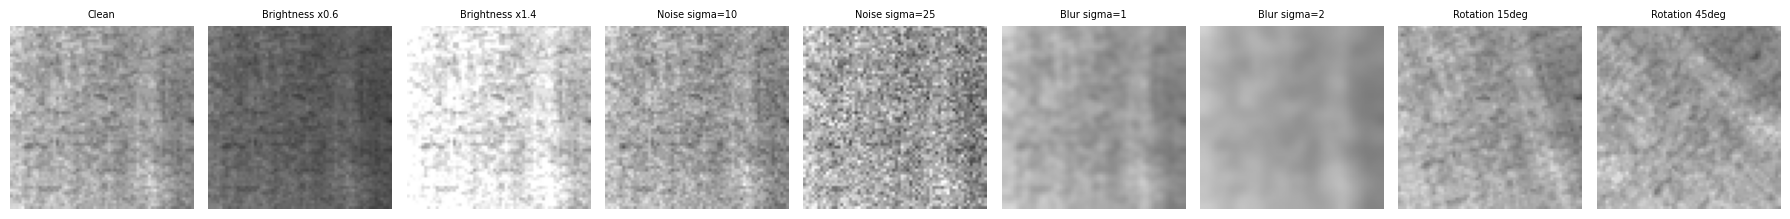

In [14]:
# Visual examples of the perturbations
i = np.where(yte == 1)[0][0]
fig, ax = plt.subplots(1, len(conditions), figsize=(2 * len(conditions), 2.4))
for a, (n, fn) in zip(ax, conditions.items()):
    a.imshow(fn(Xte_img[i]), cmap="gray", vmin=0, vmax=255); a.set_title(n, fontsize=7); a.axis("off")
plt.tight_layout(); plt.show()

## 10. Advanced: multi-class defect-type classification (whole images, 6 classes)

Multi-class HOG dims: 8100 | train (1700, 8100) | test (100, 8100)
HOG + SVM 
                  precision    recall  f1-score   support

        crazing      0.944     1.000     0.971        17
      inclusion      0.714     0.882     0.789        17
        patches      0.882     0.938     0.909        16
 pitted_surface      0.833     0.588     0.690        17
rolled-in_scale      0.944     1.000     0.971        17
      scratches      1.000     0.875     0.933        16

       accuracy                          0.880       100
      macro avg      0.886     0.881     0.877       100
   weighted avg      0.885     0.880     0.877       100

HOG + RF 
                  precision    recall  f1-score   support

        crazing      0.850     1.000     0.919        17
      inclusion      0.625     0.882     0.732        17
        patches      0.818     0.562     0.667        16
 pitted_surface      0.625     0.588     0.606        17
rolled-in_scale      0.944     1.000     0.971     

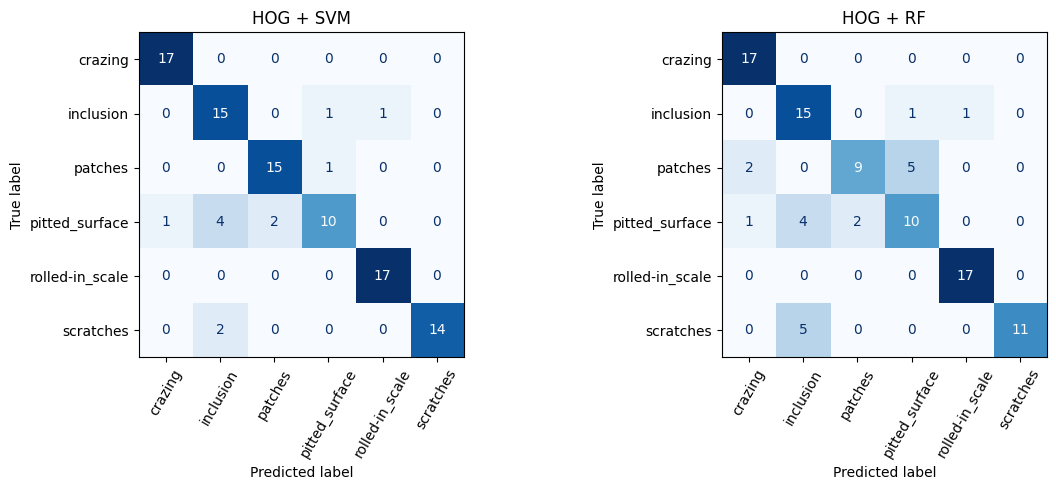

,model,accuracy,precision,recall,f1
0,HOG + SVM,0.88,0.8865,0.8805,0.8774
1,HOG + RF,0.79,0.8104,0.7868,0.7849


In [15]:
def load_mc(frame):
    X = np.array([cv2.resize(read_gray(p), (IMG_SIZE_MC, IMG_SIZE_MC), interpolation=cv2.INTER_AREA) for p in frame.path], np.uint8)
    return X, frame.label.map({c: i for i, c in enumerate(CLASSES)}).values
Xmc_tr, ymc_tr = load_mc(df[df.split == "train"]); Xmc_te, ymc_te = load_mc(df[df.split == "valid"])
Fmc_tr = extract(Xmc_tr, 8, 9); Fmc_te = extract(Xmc_te, 8, 9)
print("Multi-class HOG dims:", Fmc_tr.shape[1], "| train", Fmc_tr.shape, "| test", Fmc_te.shape)

mc_models = {"HOG + SVM": make_svm(), "HOG + RF": make_rf()}
mc_res = []
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, (n, m) in zip(ax, mc_models.items()):
    p = m.fit(Fmc_tr, ymc_tr).predict(Fmc_te)
    mc_res.append(dict(model=n, **metrics(ymc_te, p, average="macro")))
    ConfusionMatrixDisplay(confusion_matrix(ymc_te, p), display_labels=CLASSES).plot(ax=a, cmap="Blues", colorbar=False, xticks_rotation=60)
    a.set_title(n)
    print(n, "\n", classification_report(ymc_te, p, target_names=CLASSES, digits=3))
plt.tight_layout(); plt.show()
display(pd.DataFrame(mc_res).round(4))

## 11. Industrial quality-control decision module
* `inspect_patch()` – classifies one image/ROI (resized to the training resolution).
* `inspect_image()` – scans a full-size steel image with multi-scale windows; the product is **rejected if any window's P(defect) ≥ threshold**.
Both print the required report block.

In [16]:
saved = joblib.load("hog_svm_defect_model.joblib")
QC_MODEL, QC_PPC, QC_ORI, QC_SIZE, QC_T = saved["model"], saved["ppc"], saved["ori"], saved["size"], saved["thresh"]

def p_defect_batch(gray_patches):
    # one predict_proba call for many patches is far faster than one call per patch
    F = np.array([hog_feat(preprocess(g, QC_SIZE), QC_PPC, QC_ORI) for g in gray_patches], dtype=np.float32)
    return QC_MODEL.predict_proba(F)[:, 1]

def p_defect(gray_patch):
    return float(p_defect_batch([gray_patch])[0])

def report(p, thr=QC_T, extra=""):
    defective = p >= thr
    conf = (p if defective else 1 - p) * 100
    print("PRODUCT INSPECTION RESULT")
    print(f"Prediction: {'DEFECTIVE' if defective else 'NON-DEFECTIVE'}")
    print(f"Confidence: {conf:.1f}%")
    print(f"Action: {'REJECT PRODUCT' if defective else 'ACCEPT PRODUCT'}" + (f"   {extra}" if extra else ""))
    return defective

def inspect_patch(img, thr=QC_T):
    g = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return report(p_defect(g), thr)

def inspect_image(img, thr=QC_T, scales=(64, 100, 140, 200), draw=True):
    g = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    H, W = g.shape
    boxes = [(x, y, s) for s in scales if s <= min(H, W)
             for y in range(0, H - s + 1, max(s // 2, 1)) for x in range(0, W - s + 1, max(s // 2, 1))]
    best, best_box = 0.0, None
    if boxes:
        probs = p_defect_batch([g[y:y+s, x:x+s] for (x, y, s) in boxes])
        k = int(np.argmax(probs)); best, best_box = float(probs[k]), boxes[k]
    defective = report(best, thr, f"(worst window: {best_box})")
    if draw:
        vis = cv2.cvtColor(g, cv2.COLOR_GRAY2RGB)
        if defective and best_box:
            x, y, s = best_box; cv2.rectangle(vis, (x, y), (x + s, y + s), (255, 0, 0), 2)
        plt.figure(figsize=(3.2, 3.2)); plt.imshow(vis); plt.axis("off")
        plt.title("REJECT" if defective else "ACCEPT"); plt.show()
    return defective

print("---- single patches from the test split ----")
for idx in [np.where(yte == 1)[0][3], np.where(yte == 0)[0][3]]:
    print("(ground truth:", "defective" if yte[idx] else "normal", ")"); inspect_patch(Xte_img[idx]); print()

---- single patches from the test split ----
(ground truth: defective )
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 80.0%
Action: REJECT PRODUCT

(ground truth: normal )
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 71.8%
Action: REJECT PRODUCT



---- full steel images (all NEU-DET images contain defects) ----
(ground truth: rolled-in_scale)
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 85.3%
Action: REJECT PRODUCT   (worst window: (96, 96, 64))


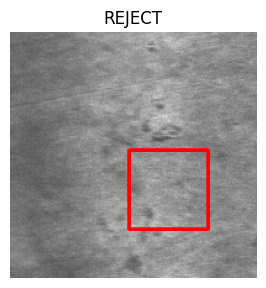


(ground truth: scratches)
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 71.0%
Action: REJECT PRODUCT   (worst window: (50, 50, 100))


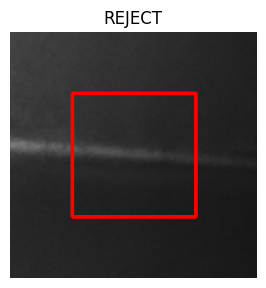


(ground truth: inclusion)
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 94.3%
Action: REJECT PRODUCT   (worst window: (128, 64, 64))


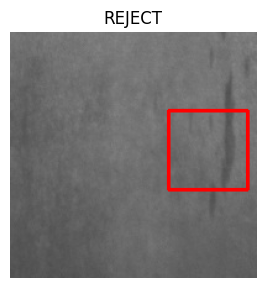


Escape rate (defects accepted): 4.3% | False-reject rate (good rejected): 63.5%


In [17]:
print("---- full steel images (all NEU-DET images contain defects) ----")
for r in df[df.split == "valid"].sample(3, random_state=1).itertuples():
    print(f"(ground truth: {r.label})"); inspect_image(read_gray(r.path)); print()

# Patch-level production metrics at the chosen threshold
proba = QC_MODEL.predict_proba(Fte)[:, 1]; pred = (proba >= QC_T).astype(int)
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
print(f"Escape rate (defects accepted): {fn/(fn+tp):.1%} | False-reject rate (good rejected): {fp/(fp+tn):.1%}")

## 12. Bonus: real-time webcam / video prototype
Set `RUN_WEBCAM = True` at the top and run on a local machine (not in a headless/cloud environment). A centred square ROI is classified every frame and shown as **PASS** / **DEFECTIVE**. Press **q** to quit. Use `source="video.mp4"` for a video file.

In [18]:
def run_realtime(source=0, roi_frac=0.6, smooth=5):
    cap = cv2.VideoCapture(source)
    if not cap.isOpened(): print("Cannot open video source"); return
    hist = []
    while True:
        ok, frame = cap.read()
        if not ok: break
        g = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY); H, W = g.shape
        s = int(min(H, W) * roi_frac); x, y = (W - s) // 2, (H - s) // 2
        hist = (hist + [p_defect(g[y:y+s, x:x+s])])[-smooth:]        # moving average removes flicker
        p = float(np.mean(hist)); bad = p >= QC_T
        col = (0, 0, 255) if bad else (0, 200, 0)
        cv2.rectangle(frame, (x, y), (x + s, y + s), col, 2)
        cv2.putText(frame, f"{'DEFECTIVE' if bad else 'PASS'}  P(def)={p:.2f}", (x, max(y - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, col, 2)
        cv2.imshow("HOG QC - press q to quit", frame)
        if cv2.waitKey(1) & 0xFF == ord("q"): break
    cap.release(); cv2.destroyAllWindows()

if RUN_WEBCAM:
    run_realtime(0)
else:
    print("Webcam demo skipped (RUN_WEBCAM=False). Simulating one frame instead:")
    sim = cv2.cvtColor(read_gray(df[df.split == 'valid'].path.iloc[0]), cv2.COLOR_GRAY2BGR)
    s = int(min(sim.shape[:2]) * 0.6); o = (sim.shape[0] - s) // 2
    print("P(defect) for central ROI:", round(p_defect(cv2.cvtColor(sim, cv2.COLOR_BGR2GRAY)[o:o+s, o:o+s]), 3))

Webcam demo skipped (RUN_WEBCAM=False). Simulating one frame instead:
P(defect) for central ROI: 0.75


## 13. Notes for the report (3–5 pages)
Fill in from the outputs above: **Introduction · Industrial application · Dataset (NEU-DET, 6 classes, 1440 train / 360 valid, 200×200; how Normal windows were derived) · Preprocessing · HOG (cell/orientation/block, feature length) · Classification (SVM-RBF, RF, k-NN, class weighting) · Experimental setup (train/valid split, CV selection) · Results (Sections 6–8, 10) · Robustness (Section 9) · Deployment (latency per image, escape vs false-reject rate, threshold choice, lighting control) · Limitations · Conclusion.**

Points worth discussing: HOG is *not* rotation-invariant (expect the largest drop under rotation); it is gradient-based so it is largely brightness-invariant but sensitive to noise/blur that alter edge strength; the Normal class is synthesised from defect-free regions of defective plates, so real production data with true defect-free plates should be used before deployment; lowering `THRESH` reduces escapes at the cost of more false rejects.